# Exploratory Data Analysis – Movie Industry Performance Dashboard
Professional Training I · Nihasrika Vijayan (44110534), Nityasri S (44110544) · Guide: Dr. M. Selvi

This notebook explores the dataset step by step, using the **same functions** as the dashboard (`src/`), so every number here matches the app and the report.

In [1]:
import sys, pandas as pd
sys.path.insert(0, '..')
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.width', 160)
from src.data_loader import load_raw_data, load_data
from src.preprocessing import clean_data, missing_values_report, find_remakes
from src import analysis, insights, figures
from src.charts import fmt_num

def show(fig):
    """Show a dashboard chart as a static PNG (keeps the notebook small)."""
    from IPython.display import Image, display
    display(Image(fig.to_image(format='png', width=1000, height=520)))

## Module 1 – Data collection
Load the CSV and look at its shape, columns and first rows.

In [2]:
raw = load_raw_data()
print(raw.shape)
raw.head()

(5421, 15)


,Movie Title,Genre,Sum of Release year,Sum of Revenue,Sum of Rating Score,Director,Star,Sum of Budget,Sum of Votes,Sum of Runtime,Country,Company,Released,Writer,Rating
0,*batteries not included,Comedy,1987,65088797,6.70,Matthew Robbins,Hume Cronyn,25000000,32000,106,United States,Universal Pictures,"December 18, 1987 (United States)",Mick Garris,PG
1,[Rec]²,Horror,2009,18853164,6.50,Jaume Balagueró,Jonathan D. Mellor,5600000,70000,85,Spain,Filmax,"October 2, 2009 (Spain)",Jaume Balagueró,R
2,10 Cloverfield Lane,Action,2016,110216998,7.20,Dan Trachtenberg,John Goodman,15000000,300000,103,United States,Paramount Pictures,"March 11, 2016 (United States)",Josh Campbell,PG-13
3,10 Things I Hate About You,Comedy,1999,53478579,7.30,Gil Junger,Heath Ledger,30000000,309000,97,United States,Touchstone Pictures,"March 31, 1999 (United States)",Karen McCullah,PG-13
4,10 to Midnight,Crime,1983,7175592,6.30,J. Lee Thompson,Charles Bronson,4520000,7200,101,United States,Cannon Films,"March 11, 1983 (United States)",William Roberts,R


In [3]:
raw.dtypes

Movie Title                str
Genre                      str
Sum of Release year      int64
Sum of Revenue           int64
Sum of Rating Score    float64
Director                   str
Star                       str
Sum of Budget            int64
Sum of Votes             int64
Sum of Runtime           int64
Country                    str
Company                    str
Released                   str
Writer                     str
Rating                     str
dtype: object

In [4]:
df_renamed = load_data()
list(df_renamed.columns)

['title',
 'genre',
 'year',
 'revenue',
 'score',
 'director',
 'star',
 'budget',
 'votes',
 'runtime',
 'country',
 'company',
 'released',
 'writer',
 'certificate']

## Module 2 – Data preprocessing
Missing values, duplicates and inconsistent labels.

In [5]:
missing_values_report(df_renamed).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Column,title,genre,year,revenue,score,director,star,budget,votes,runtime,country,company,released,writer,certificate
Missing values,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [6]:
print('Exact duplicate rows:', df_renamed.duplicated().sum())
print('Same title + year   :', df_renamed.duplicated(['title', 'year']).sum())
print('Titles used twice+  :', df_renamed['title'].duplicated().sum())

Exact duplicate rows: 0
Same title + year   : 0
Titles used twice+  : 85


In [7]:
df_renamed['certificate'].value_counts()

certificate
R            2597
PG-13        1729
PG            907
G             111
Not Rated      44
Unrated        17
NC-17          12
TV-MA           2
X               1
Approved        1
Name: count, dtype: int64

In [8]:
df, log = clean_data(df_renamed)
log

,Step,What was done,Rows before,Rows after,Values / rows affected
0,1. Trim text,Removed extra spaces from text columns,5421,5421,0
1,2. Fix data types,"Converted year, revenue, score, budget, votes,...",5421,5421,0
2,3a. Missing critical values,"Dropped rows with no title, genre, year or rev...",5421,5421,0
3,3b. Fill other gaps,"Text gaps -> 'Unknown', number gaps -> column ...",5421,5421,0
4,4. Exact duplicates,Removed rows that are identical in every column,5421,5421,0
5,5. Title + year duplicates,Removed the same movie listed twice in one year,5421,5421,0
6,6. Standardise certificates,Merged 'Unrated' into 'Not Rated' (same meaning),5421,5421,17
7,7. Validate ranges,"Dropped rows with score outside 0-10, bad year...",5421,5421,0
8,8. Add helper columns,"Added profit, ROI, release_date, release_count...",5421,5421,0


In [9]:
find_remakes(df).head(10)

,title,year,genre,director,revenue
0,A Nightmare on Elm Street,1984,Horror,Wes Craven,25507137
1,A Nightmare on Elm Street,2010,Crime,Samuel Bayer,115695182
2,Aladdin,1992,Animation,Ron Clements,504050219
3,Aladdin,2019,Adventure,Guy Ritchie,1050693953
4,Anna Karenina,1997,Drama,Bernard Rose,858553
5,Anna Karenina,2012,Drama,Joe Wright,68929150
6,Annie,1982,Comedy,John Huston,57063861
7,Annie,2014,Comedy,Will Gluck,136853506
8,Bad Company,1995,Crime,Damian Harris,3674841
9,Bad Company,2002,Action,Joel Schumacher,66200782


### Totals check (must match Power BI)

In [10]:
k = analysis.kpis(df)
print('Movies            :', k['movies'])
print('Total revenue     :', fmt_num(k['revenue']), f"({k['revenue']:,})")
print('Total budget      :', fmt_num(k['budget']), f"({k['budget']:,})")
print('Sum of score      :', round(k['score_sum'], 1))

Movies            : 5421
Total revenue     : 560bn (559,607,950,720)
Total budget      : 195bn (195,205,713,119)
Sum of score      : 34653.5


In [11]:
df[['year', 'revenue', 'budget', 'score', 'votes', 'runtime']].describe()

,year,revenue,budget,score,votes,runtime
count,"5,421.00","5,421.00","5,421.00","5,421.00","5,421.00","5,421.00"
mean,"2,001.66","103,229,653.33","36,009,170.47",6.39,"115,066.13",108.15
std,10.54,"187,302,717.15","41,573,373.99",0.96,"184,407.26",18.12
min,"1,980.00",309.00,"6,000.00",1.90,195.00,63.00
25%,"1,993.00","10,736,401.00","10,000,000.00",5.80,"19,000.00",95.00
50%,"2,002.00","36,869,414.00","21,800,000.00",6.50,"52,000.00",105.00
75%,"2,011.00","112,462,508.00","45,000,000.00",7.10,"129,000.00",118.00
max,"2,020.00","2,847,246,203.00","356,000,000.00",9.30,"2,400,000.00",271.00


## Module 3 – Revenue & genre analysis

In [12]:
analysis.genre_summary(df)

,genre,total_revenue,avg_revenue,median_revenue,movies,avg_score,revenue_share
0,Action,237752868767,"168,023,228.81","71,416,730.00",1415,6.25,0.42
1,Comedy,88514817620,"59,167,658.84","27,394,834.00",1496,6.19,0.16
2,Animation,77865909110,"281,104,365.02","192,306,508.00",277,6.69,0.14
3,Drama,52098564769,"60,369,136.46","22,007,671.00",863,6.72,0.09
4,Adventure,43578711908,"133,268,232.13","43,411,001.00",327,6.27,0.08
5,Crime,20017662162,"50,169,579.35","18,753,438.00",399,6.69,0.04
6,Biography,19093930296,"61,395,274.26","33,013,805.00",311,7.09,0.03
7,Horror,14261055032,"56,816,952.32","30,553,394.00",251,5.83,0.03
8,Family,2074332587,"518,583,146.75","403,889,034.00",4,6.67,0.00
9,Mystery,2004091467,"117,887,733.35","23,726,793.00",17,6.67,0.00


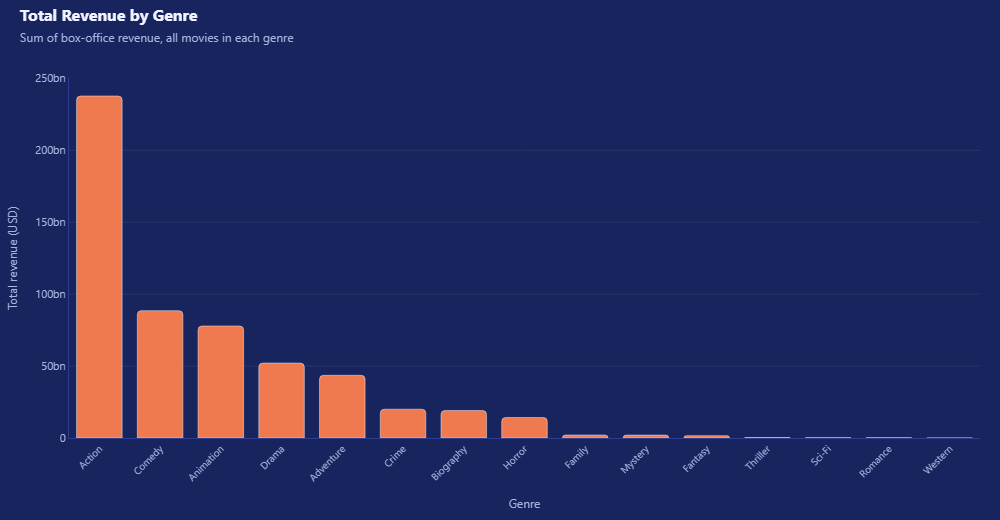

In [13]:
show(figures.revenue_by_genre(df))

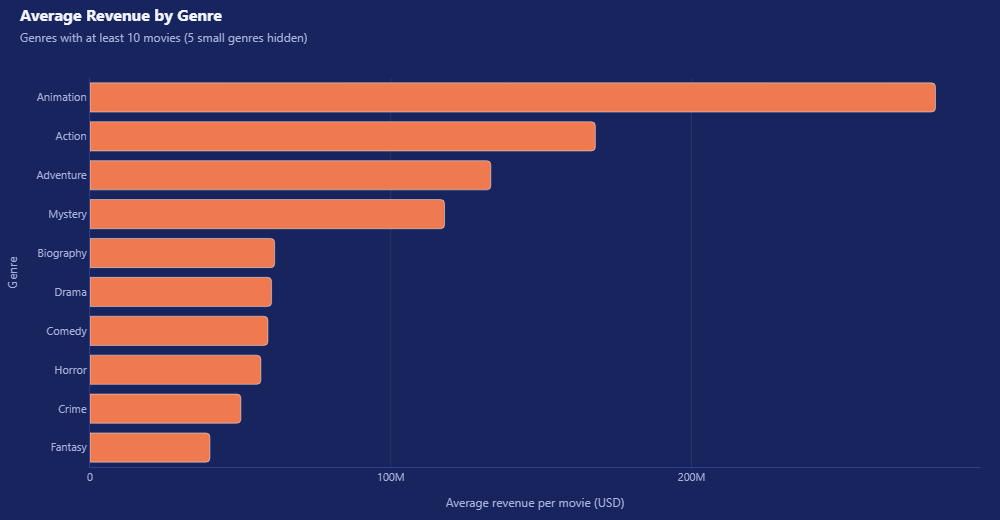

In [14]:
show(figures.avg_revenue_by_genre(df, 10))

In [15]:
analysis.revenue_growth(df)

{'ok': True,
 'first_years': (1980, 1984),
 'last_years': (2016, 2020),
 'first_total': np.int64(11622323487),
 'last_total': np.int64(113051454595),
 'growth_pct': np.float64(872.709585320459),
 'peak_year': 2016,
 'peak_revenue': np.int64(27847564254)}

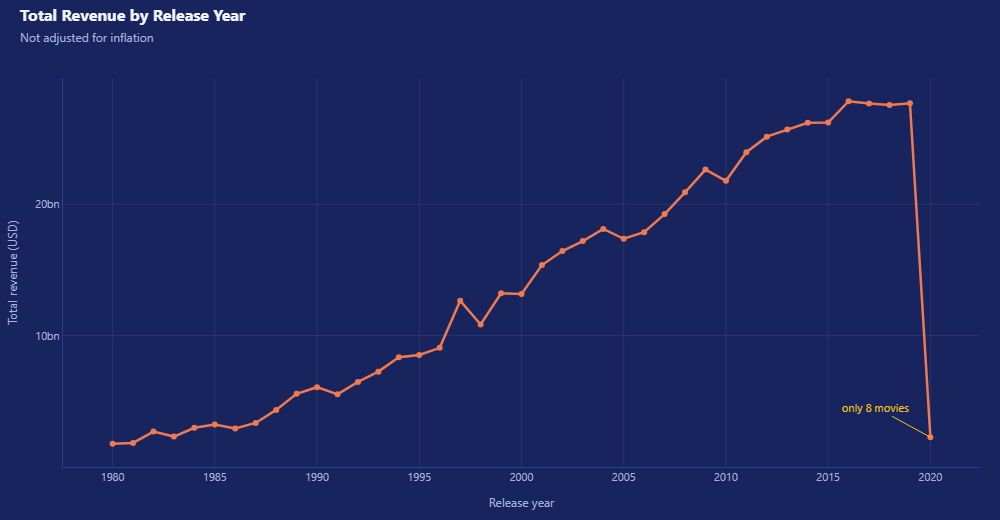

In [16]:
show(figures.revenue_by_year(df))

## Module 4 – Rating trend analysis

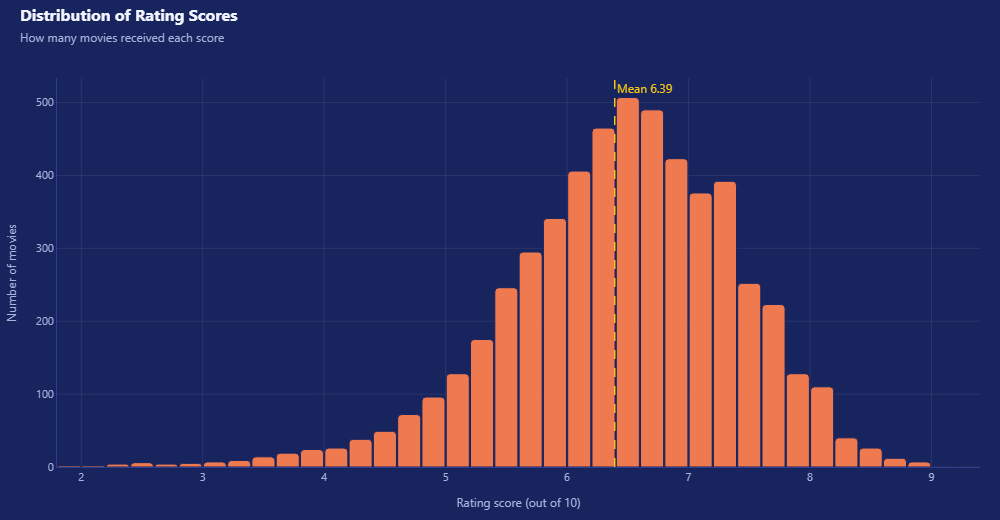

In [17]:
show(figures.score_distribution(df))

In [18]:
analysis.score_by_group(df, 'genre', 10)

,genre,avg_score,median_score,movies,avg_revenue
0,Biography,7.09,7.10,311,"61,395,274.26"
1,Drama,6.72,6.80,863,"60,369,136.46"
2,Animation,6.69,6.70,277,"281,104,365.02"
3,Crime,6.69,6.60,399,"50,169,579.35"
4,Mystery,6.67,6.70,17,"117,887,733.35"
5,Adventure,6.27,6.40,327,"133,268,232.13"
6,Action,6.25,6.30,1415,"168,023,228.81"
7,Comedy,6.19,6.30,1496,"59,167,658.84"
8,Fantasy,6.05,6.10,41,"39,878,697.78"
9,Horror,5.83,5.90,251,"56,816,952.32"


In [19]:
analysis.score_by_group(df, 'certificate', 10)

,certificate,avg_score,median_score,movies,avg_revenue
0,Not Rated,6.87,6.80,61,"16,142,349.52"
1,NC-17,6.66,7.10,12,"15,942,256.75"
2,G,6.56,6.70,111,"189,245,253.81"
3,R,6.50,6.50,2597,"55,910,594.63"
4,PG-13,6.29,6.40,1729,"154,159,800.14"
5,PG,6.22,6.40,907,"137,739,573.91"


In [20]:
for a, b in [('score', 'revenue'), ('votes', 'revenue'), ('votes', 'score'), ('budget', 'revenue')]:
    r = analysis.correlation(df, a, b)
    print(f'{a:>6} vs {b:<8} r = {r:.3f}  ({insights.describe_correlation(r)})')

 score vs revenue  r = 0.223  (weak positive)
 votes vs revenue  r = 0.615  (strong positive)
 votes vs score    r = 0.474  (moderate positive)
budget vs revenue  r = 0.740  (strong positive)


In [21]:
analysis.score_bands(df)

,score_band,movies,avg_revenue
0,Below 5,377,"48,103,657.88"
1,5 - 6,1185,"64,918,704.06"
2,6 - 7,2291,"95,750,852.67"
3,7 - 8,1371,"136,984,477.75"
4,8 and above,197,"291,234,948.82"


## Module 5 – Actor & director analysis

In [22]:
analysis.top_people_by_revenue(df, 'star', 10)

,star,total_revenue,avg_revenue,movies,avg_score
0,Robert Downey Jr.,11855937746,"623,996,723.47",19,7.06
1,Tom Hanks,9899944903,"260,524,865.87",38,7.09
2,Tom Cruise,9440309875,"286,069,996.21",33,6.83
3,Will Smith,7947279234,"345,533,879.74",23,6.71
4,Johnny Depp,7410125354,"239,036,301.74",31,6.95
5,Daniel Radcliffe,6971268037,"697,126,803.70",10,7.30
6,Leonardo DiCaprio,6963367648,"348,168,382.40",20,7.50
7,Vin Diesel,6036312568,"402,420,837.87",15,6.39
8,Dwayne Johnson,5711270624,"259,603,210.18",22,6.14
9,Bruce Willis,5318951036,"156,439,736.35",34,6.51


In [23]:
analysis.top_people_by_revenue(df, 'director', 10)

,director,total_revenue,avg_revenue,movies,avg_score
0,Steven Spielberg,9629049370,"356,631,458.15",27,7.44
1,Anthony Russo,6844248984,"1,368,849,796.80",5,7.58
2,Peter Jackson,6618045788,"601,640,526.18",11,7.75
3,Michael Bay,6451692798,"496,284,061.38",13,6.48
4,James Cameron,6248088578,"892,584,082.57",7,7.87
5,Christopher Nolan,5153547948,"468,504,358.91",11,8.16
6,David Yates,5044548416,"840,758,069.33",6,7.20
7,J.J. Abrams,4659375464,"776,562,577.33",6,7.30
8,Tim Burton,4456348890,"234,544,678.42",19,6.98
9,Ron Howard,4388092562,"190,786,633.13",23,6.83


In [24]:
analysis.top_people_by_score(df, 'director', 10, min_movies=5)

,director,total_revenue,avg_revenue,movies,avg_score
0,Christopher Nolan,5153547948,"468,504,358.91",11,8.16
1,Quentin Tarantino,1870119160,"207,791,017.78",9,8.10
2,Hayao Miyazaki,963600536,"192,720,107.20",5,8.10
3,Denis Villeneuve,676821463,"135,364,292.60",5,7.98
4,James Cameron,6248088578,"892,584,082.57",7,7.87
5,David Fincher,2142317821,"214,231,782.10",10,7.76
6,Alejandro G. Iñárritu,852832085,"170,566,417.00",5,7.76
7,Peter Jackson,6618045788,"601,640,526.18",11,7.75
8,Martin Scorsese,2094150897,"110,218,468.26",19,7.67
9,Alfonso Cuarón,1656659302,"331,331,860.40",5,7.60


In [25]:
print('Top 10 directors share of revenue:', f"{analysis.top_n_share(df, 'director', 10):.1%}")
print('Top 10 stars share of revenue    :', f"{analysis.top_n_share(df, 'star', 10):.1%}")

Top 10 directors share of revenue: 10.6%
Top 10 stars share of revenue    : 13.9%


## Budget & ROI

In [26]:
analysis.roi_by_genre(df, 10)

,genre,median_roi,median_profit,total_profit,movies
0,Horror,2.08,"19,795,897.00",10888988032,251
1,Animation,1.92,"121,705,322.00",56724339110,277
2,Fantasy,1.14,"10,738,769.00",928826609,41
3,Mystery,0.98,"11,726,793.00",1462191466,17
4,Adventure,0.88,"17,610,873.00",28550151908,327
5,Action,0.87,"28,718,711.00",155019855699,1415
6,Comedy,0.79,"9,416,101.00",54402469405,1496
7,Drama,0.53,"4,760,107.00",32040824782,863
8,Biography,0.47,"9,540,607.00",11181571528,311
9,Crime,0.30,"2,700,000.00",10999106082,399


In [27]:
print('Share of movies that lost money:', f'{analysis.loss_share(df):.1%}')
analysis.top_profit_movies(df, 10)

Share of movies that lost money: 32.2%


,title,year,genre,budget,revenue,profit,roi
0,Avatar,2009,Action,237000000,2847246203,2610246203,11.01
1,Avengers: Endgame,2019,Action,356000000,2797501328,2441501328,6.86
2,Titanic,1997,Drama,200000000,2201647264,2001647264,10.01
3,Star Wars: Episode VII - The Force Awakens,2015,Action,245000000,2069521700,1824521700,7.45
4,Avengers: Infinity War,2018,Action,321000000,2048359754,1727359754,5.38
5,Jurassic World,2015,Action,150000000,1670516444,1520516444,10.14
6,The Lion King,2019,Animation,260000000,1670727580,1410727580,5.43
7,Furious 7,2015,Action,190000000,1515341399,1325341399,6.98
8,Frozen II,2019,Animation,150000000,1450026933,1300026933,8.67
9,The Avengers,2012,Action,220000000,1518815515,1298815515,5.90


## Module 6 – Insights generated from the data

In [28]:
for card in insights.key_insights(df):
    print(card['title']); print('  ', card['text']); print('   Takeaway:', card['takeaway']); print()
for fact in insights.extra_insights(df):
    print('-', fact)

1. REVENUE GROWTH
   Movies released in 2016-2020 earned 113bn, 873% higher than the 11.6bn earned in 1980-1984. The peak year was 2016 (27.8bn). Note: 2020 has only 8 movies.
   Takeaway: Revenue has grown over time (figures are not inflation-adjusted).

2. GENRE PERFORMANCE
   Action leads with 238bn, 42% of all revenue from 1,415 movies. The top 3 genres together earn 72%.
   Takeaway: Revenue is concentrated: Action earns over twice an even share.

3. DIRECTOR IMPACT
   The top 10 of 2,063 directors earn 11% of revenue while making only 2% of the movies. Steven Spielberg leads with 9.6bn from 27 films.
   Takeaway: Top directors earn 4.5x their share of movies.

4. AUDIENCE RATINGS
   Score vs revenue correlation is 0.22 (weak positive); votes vs revenue is 0.61 (strong positive). Biography has the highest average score (7.09).
   Takeaway: Popularity (votes) is linked to revenue more than the score is.

- R is the most common certificate (48% of movies).
- Horror has the best medi